### Physics 155, Fall 2026, Rutgers University--New Brunswick
# ***Europa Project***

## Exogenous Heat

In [1]:
import os
import sys
import matplotlib.pyplot as plt
from brokenaxes import brokenaxes 
import pdb
import numpy as np
import os as os_module
from scipy.integrate import solve_ivp
import pandas as pd
from matplotlib import ticker
import scipy as sp
from scipy.integrate import cumulative_trapezoid, trapezoid, odeint, solve_bvp, solve_ivp
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib import colormaps
import matplotlib.ticker as mtick
from matplotlib.ticker import EngFormatter, LogLocator, FuncFormatter, NullFormatter, FixedLocator, StrMethodFormatter, LogFormatter, LogFormatterSciNotation, LogFormatterExponent, LogFormatterMathtext, FixedFormatter
from matplotlib.lines import lineStyles
import cmocean
import cmocean.cm as cmo
from matplotlib.colors import LogNorm
from IPython.display import clear_output
import matplotlib.patheffects as pe
from matplotlib.collections import LineCollection
from labellines import labelLines
from itertools import cycle

In [39]:
planets_data = { 'Name': [ 'Mercury', 'Venus', 'Earth', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune', ], 
                'temp_K': [440.15, 737.15, 288.15, 208.15, 163.15, 133.15, 78.15, 73.15], 
                'dist_m': [ 5.7909227e10, 1.08209475e11, 1.49598262e11, 2.27943824e11, 7.78340821e11, 1.426666422e12, 2.870658186e12, 4.498396441e12, ], 
                }

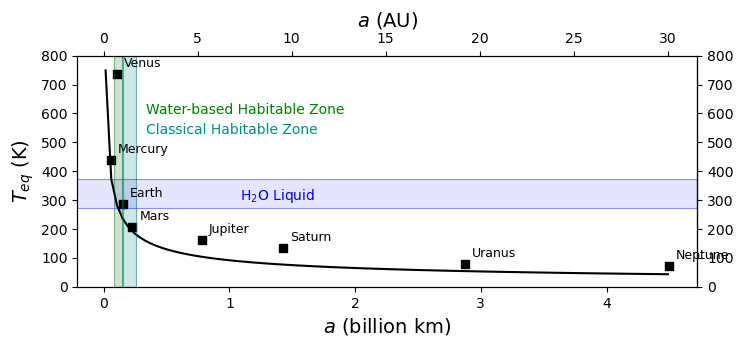

In [221]:
emissivity_Lange = 0.9 # Lange et al. 2026: Spencer et al. 1999 value (https://www.aanda.org/articles/aa/pdf/2026/09/aa60450-26.pdf)
emissivity_Trumbo = 0.75 # Trumbo et al. 2018, global best-fit value
T_sun = 5.8e3 # (K) solar surface temperature
A = 0.64 # Europa's albedo, Lange et al. 2026
A_rocky = 0.3 # Albedo of rocky planets
r_sun = 6.96e8 # (m) solar radius
AU_m = 1.496e11 # (m) astronomical unit
emissivity_planets = 0.7 # average value for all solar system planets
a = np.linspace(0.1, 30, 100)*AU_m # (AU) Jupiter's semi-major axis

Teq = T_sun * ((1 - A)/emissivity_planets)**(1/4) * (r_sun / (2 * a))**(1/2)

a_hab_outer = r_sun / ( 2 * (273 / (T_sun * ((1 - A_rocky)/emissivity_planets)**(1/4)))**2 )
a_hab_inner = r_sun / ( 2 * (373 / (T_sun * ((1 - A_rocky)/emissivity_planets)**(1/4)))**2 )

fig, ax1 = plt.subplots(figsize=(8, 3))
ax1.plot(a/1e12, Teq, lw=1.5, color='black')
ax1.set_xlabel('$a$ (billion km)', fontsize=14)
ax1.set_ylabel('$T_{eq}$ (K)', fontsize=14)
ax1.xaxis.set_major_formatter(StrMethodFormatter('{x:g}'))
ax1.vlines(x=[a_hab_inner/1e12, a_hab_outer/1e12], ymin=0, ymax=800, color='green', ls='-', lw=0.5, alpha=0.5)
ax1.vlines(x=[0.95*AU_m/1e12, 1.7*AU_m/1e12], ymin=0, ymax=800, color='darkcyan', ls='-', lw=0.5, alpha=0.7)
ax1.text(y=300, x=a_hab_inner/1e12+1, s='H$_2$O Liquid', fontsize=10, color='blue')
ax1.axhline(y=273, color='blue',lw=0.5, alpha=0.5) 
ax1.axhline(y=373, color='blue',lw=0.5, alpha=0.5)
ax1.text(a_hab_inner/1e12+0.25, 600, 'Water-based Habitable Zone', fontsize=10, color='green')
ax1.text(a_hab_inner/1e12+0.25, 530, 'Classical Habitable Zone', fontsize=10, color='darkcyan')
ax1.axvspan(a_hab_inner/1e12, a_hab_outer/1e12, color='green', alpha=0.2)
ax1.axvspan(0.95*AU_m/1e12, 1.7*AU_m/1e12, color='darkcyan', alpha=0.2)
ax1.axhspan(273, 373, color='blue', alpha=0.1)
ax1.set_ylim(0, 800)

ax3 = ax1.secondary_yaxis('right')

planet_distance = [a/1e12 for a in planets_data['dist_m']] 
ax1.scatter(planet_distance, planets_data['temp_K'], color='black', marker='s') 
for name, x_val, y_val in zip(planets_data['Name'], planet_distance, planets_data['temp_K'] ): 
    ax1.annotate( name, (x_val, y_val), textcoords='offset points', xytext=(5, 5), fontsize=9)

ax2 = ax1.twiny() 
ax2.set_xlim(np.array(ax1.get_xlim())*1e12/AU_m)
ax2.set_xlabel('$a$ (AU)', fontsize=14) 
ax2.xaxis.set_major_formatter(StrMethodFormatter('{x:.0f}'))




In [222]:
a_jup = 5.2*1.496e11  # Jupiter's orbital distance
Teq = T_sun * ((1 - A)/emissivity_Trumbo)**(1/4) * (r_sun / (2 * a_jup))**(1/2)
print(f'At a distance of {a_jup/1.496e11} AU, the equilibrium temperature is {Teq:.1f} K ({Teq-273:.1f} °C)')
a_earth = 1.0*1.496e11  # Earth's orbital distance
Teq_earth = T_sun * ((1 - A)/emissivity_planets)**(1/4) * (r_sun / (2 * a_earth))**(1/2)
print(f'At a distance of {a_earth/1.496e11:.0f} AU, the equilibrium temperature is {Teq_earth:.1f} K ({Teq_earth-273:.1f} °C)')

At a distance of 5.2 AU, the equilibrium temperature is 102.1 K (-170.9 °C)
At a distance of 1 AU, the equilibrium temperature is 236.9 K (-36.1 °C)


In [69]:
print(f"Habitable zone: {a_hab_inner/AU_m:.2f} AU to {a_hab_upper/AU_m:.2f} AU")

Habitable zone: 1.44 AU to 0.77 AU


## Endogenous Heat